<a href="https://colab.research.google.com/github/HONGSAHUN/AI-Class/blob/main/Week06_1012/DL_digits_1012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 손글씨 숫자 ML → 딥러닝 분류

In [1]:
import matplotlib.pyplot as plt

In [2]:
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split

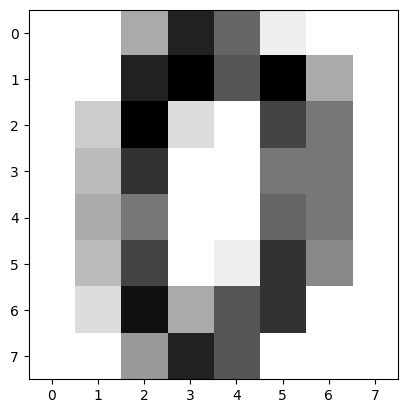

In [3]:
digits = datasets.load_digits()
plt.imshow(digits.images[0], cmap = plt.cm.gray_r, interpolation='nearest')

In [4]:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

In [5]:
from sklearn.neighbors import KNeighborsClassifier

In [6]:
knn = KNeighborsClassifier(n_neighbors=4)
X_train, X_test, y_train, y_test = train_test_split(data, digits.target, test_size = 0.2)

In [7]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=4)

In [8]:
y_pred = knn.predict(X_test)

scores = metrics.accuracy_score(y_test, y_pred)
print(scores)

0.9861111111111112


[4]


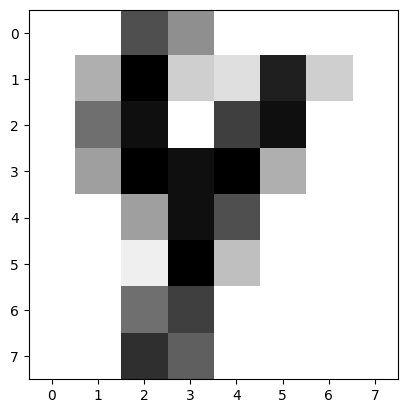

In [9]:
plt.imshow(X_test[10].reshape(8, 8), cmap = plt.cm.gray_r, interpolation = 'nearest')
y_pred = knn.predict([X_test[10]])
print(y_pred)

In [10]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
print("Decision Tree:", metrics.accuracy_score(y_test, dt_pred))

Decision Tree: 0.8416666666666667


In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
print("Random Forest:", metrics.accuracy_score(y_test, rf_pred))

Random Forest: 0.9888888888888889


In [12]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
print("Logistic Regression:", metrics.accuracy_score(y_test, lr_pred))

Logistic Regression: 0.9555555555555556


In [13]:
models = {"KNN": knn, "Decision Tree": dt, "Random Forest": rf, "Logistic Regression": lr}

for name, model in models.items():
    acc = metrics.accuracy_score(y_test, model.predict(X_test))
    print(f"{name:<20} {acc:.4f}")

KNN                  0.9861
Decision Tree        0.8417
Random Forest        0.9889
Logistic Regression  0.9556


# 딥러닝 분류

In [14]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

print(np.bincount(digits.target))
print("레이블 최솟값:", digits.target.min())

X_dl = data / 16.0
y_dl = digits.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_dl, y_dl, test_size=0.2, random_state=42, stratify=y_dl)
print(Xd_train.shape, yd_train.shape)

[178 182 177 183 181 182 181 179 174 180]
레이블 최솟값: 0
(1437, 64) (1437,)


In [15]:
dl_model = tf.keras.Sequential([
    tf.keras.Input(shape=(64,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
dl_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
dl_model.summary()

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = dl_model.fit(Xd_train, yd_train, epochs=200, batch_size=32,
                       validation_split=0.2, callbacks=[es], verbose=0)
print("학습한 epoch 수:", len(history.history['loss']))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

학습한 epoch 수: 44


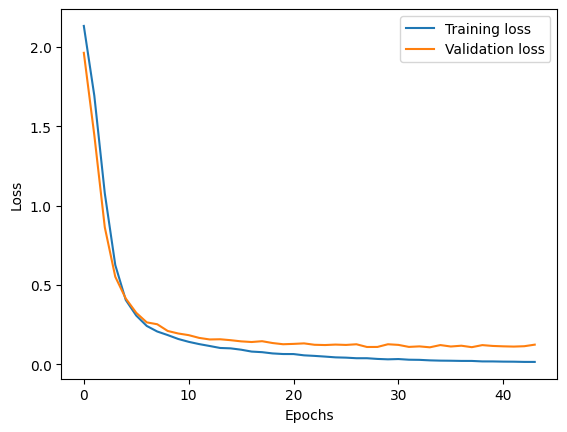

In [16]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.show()

In [17]:
yd_pred = np.argmax(dl_model.predict(Xd_test), axis=1)
print("DL Accuracy:", metrics.accuracy_score(yd_test, yd_pred))
print(confusion_matrix(yd_test, yd_pred))
print(classification_report(yd_test, yd_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
DL Accuracy: 0.975
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 35  0  0  0  0  1  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 36  0  1  0  0  0  0]
 [ 0  0  0  0 35  0  1  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  2  0  0  0  0  0  1 32  0]
 [ 0  0  0  0  0  0  0  1  0 35]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      0.97      0.99        37
           4       0.97      0.97      0.97        36
           5       0.97      1.00      0.99        37
           6       0.95      0.97      0.96        36
           7       0.95      1.00      0.97        36
           8       0.97      0.91      0.94        35
           9       1.00      0.97      0.99        36

    accuracy  

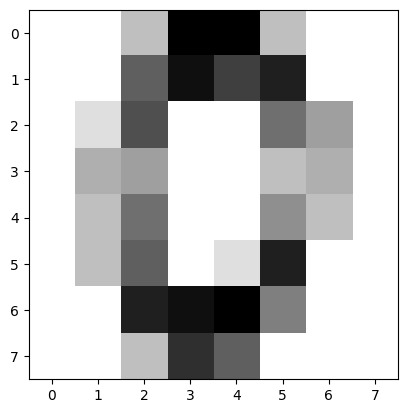

실제: 0 / 예측: 0


In [18]:
idx = 10
plt.imshow(Xd_test[idx].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()
print("실제:", yd_test[idx], "/ 예측:", yd_pred[idx])

## 원-핫 버전

In [19]:
yd_train_oh = tf.keras.utils.to_categorical(yd_train, num_classes=10)

dl_model_oh = tf.keras.Sequential([
    tf.keras.Input(shape=(64,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
dl_model_oh.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
dl_model_oh.fit(Xd_train, yd_train_oh, epochs=200, batch_size=32,
                validation_split=0.2, callbacks=[es], verbose=0)
print("One-hot DL Accuracy:", metrics.accuracy_score(yd_test, np.argmax(dl_model_oh.predict(Xd_test), axis=1)))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
One-hot DL Accuracy: 0.9777777777777777
